# LASSI - Power Efficiency

***OLLAMA API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

## Setup

In [4]:
import os

# Import LASSI modules
import lassi.llm_config
import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1
    
# We need to reload the prompt dictionary because it is under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.pipeline
%aimport lassi.get_power

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [5]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.

    -- matrix-rotate ["10000", "1"]
    -- jacobi [""] (none required)
    -- DNU -- mallocFree ["10000"]
    -- layout ["1"]
    -- atomicCost ["1"]
    -- dense-embedding ["10000", "8", "1"]
    -- pathfinder ["10000", "1000", "1000"]
    -- bsearch ["10000", "1"]
    -- entropy ["10000", "1024", "1"]
    -- colorwheel ["10000", "8", "1"]
    -- randomAccess ["1"]
    -- lid-driven-cavity [""]
    """
    
    app_folder_name = "lid-driven-cavity"

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context = True  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    if source_lang == "CUDA":
        code_compiler = "nvcc"
        code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
        # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = [""]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM LMSTUDIO
    # model = "lmstudio-community/Meta-Llama-3-8B-Instruct-GGUF/"
    # model = "TheBloke/CodeLlama-13B-Instruct-GGUF"
    # model = "lmstudio-community/starcoder2-15b-instruct-v0.1-GGUF" - couldn;t generate anything
    # model = "lmstudio-community/stable-code-instruct-3b-GGUF" - couldn't compile, but 'worked'
    # model = "microsoft/Phi-3-mini-4k-instruct-gguf" - generated garbage, and slow
    # model = "lmstudio-community/codegemma-1.1-7b-it-GGUF" - generated code, faster, but not compiled -- more tries
    # model = "lmstudio-community/Codestral-22B-v0.1-GGUF"  # - nice large context size 32768 -- load it on aiop01 at 28 gpu layers

    # -- FROM OLLAMA
    # model = "deepseek-r1:70b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model = "deepseek-coder-v2"  # (max token = 16384)
    # model = "codestral"  # (max token = 32768)
    # model = "qwq:latest"  # (max token = 32768)
    # model = "qwen2.5-coder:32b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 128000

    # ASSIGN LLM API SOURCE:
    if "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "01test_betterpower_withcontext"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)

    return (app_folder_name, source_lang, target_lang, model, num_ctx, llm_source, use_context,
            context_knowledge_selection, code_compiler, code_compiler_kwds, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


Unloading Ollama server...

Unload LLM:
 {"model":"llama3.3:latest","created_at":"2025-01-30T14:19:44.501921637Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   167  100   122  100    45   1739    641 --:--:-- --:--:-- --:--:--  2420


***** EXPERIMENT CONFIGURATION SUMMARY *****

Application: lid-driven-cavity

EE Refactoring: CUDA_ee

LLM Source: ollama
Model: llama3.3:latest
System Prompt Index: CUDA
Code file template: generated_codes/ollama_llama3.3:latest/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext

LLM System Prompt: 

You are a professional coding AI assistant that specializes in refactoring parallelized code to improve energy efficiency by reducing GPU and CPU power consumption. W

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Execute command: ['./lid-driven-cavity-cuda_main', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 92522, res = 9.999751e-04
Time = 0.000954, delt = 4.768372e-04, iter = 88410, res = 9.999561e-04
Time = 0.001000, delt = 4.632568e-05, iter = 86674, res = 9.999808e-04

Total execution time of the iteration loop: 10.140251 (s)
GPU power data has been written to source_CUDA_gpu_power_results.csv


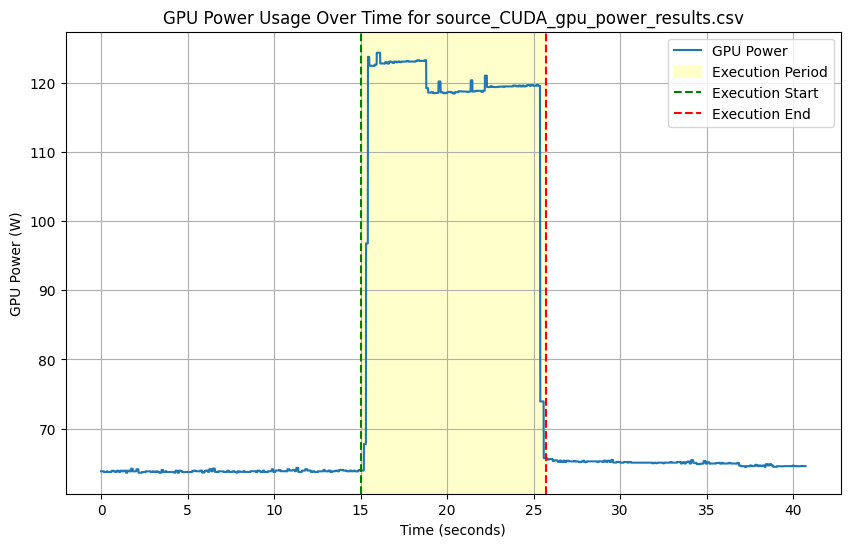

Start time: 15.015 -- End time: 25.709

... Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 10.69 seconds
Total GPU energy consumption for source_CUDA_gpu_power_results.csv:
  0.000348 kWh
  0.3480 Wh
  1252.67 J
Average GPU power: 117.18 W
Total Energy During Exe Runtime:   1252.67 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


Measure system idle power...
... Duration for idle time measurement: 10.693385601043701
GPU power data has been written to idle__gpu_power_results.csv


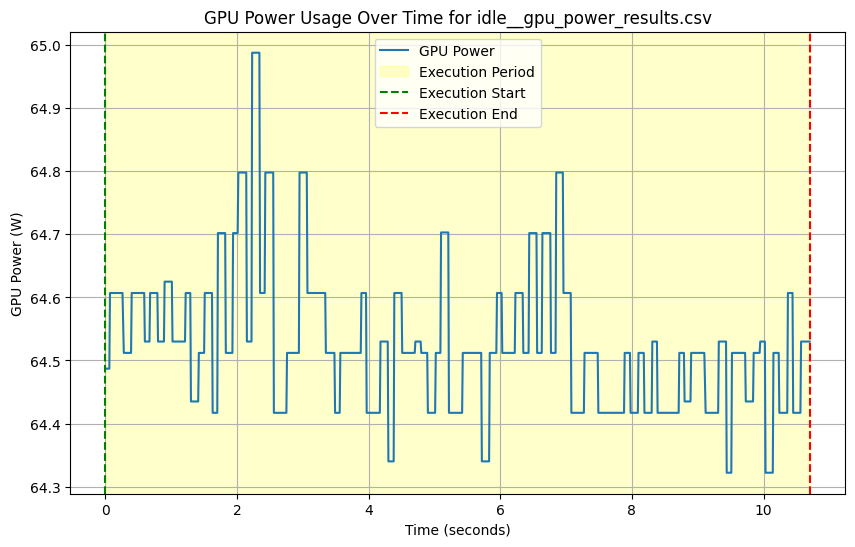

Start time: 0 -- End time: 10.704

... Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 10.70 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000192 kWh
  0.1920 Wh
  691.08 J
Average GPU power: 64.53 W
Total Energy During Exe Runtime:   691.08 J
----------------------------------------------------------------------------------------------------------------------------------------





----- STARTING LLM CONTEXT BUILDING WITH SELF-PROMPTING -----



--> ... prompt LLM to summarize context knowledge.




----- CONTEXT KNOWLEDGE SUMMARY -----
(generated by the LLM)



This text provides guidelines for optimizing CUDA code. Here are the main points summarized:

**High Priority:**

1. **Minimize global memory access**: Prefer shared memory access where possible, as global memory access can have hundreds of clock cycles of latency.
2. **Avoid different execution paths within the same warp**: Flow control instructions (if, switch, do, for, while) can cause threads to diverge, increasing instruction throughput. Try to minimize divergent warps by writing controlling conditions that align with warp boundaries.

**Medium Priority:**

1. **Use branch predication**: The compiler may use branch predication instead of loops or control statements, which can eliminate warp divergence.
2. **Optimize memory access patterns**: Use coalesced memory access and avoid strided access to minimize memory latency.

**Low Priority:**

1. **Make it easy for the compiler to unroll loops**: Use `#pragma unroll` to control loop unrolling and help the compiler optimize out if or switch statements.
2. **Use predicated instructions**: The compiler may replace branch instructions with predicated instructions, which can reduce warp divergence.

**Additional Tips:**

1. **Prefer shared memory over local memory**: Shared memory is faster and more efficient than local memory.
2. **Avoid using too many registers**: Using too many registers can lead to register spilling, which can slow down the code.
3. **Use CUDA's built-in functions**: CUDA provides optimized functions for common mathematical operations, such as `sinpi` and `cospif`, which can be faster and more accurate than implementing them manually.

By following these guidelines, developers can optimize their CUDA code to achieve better performance and efficiency on NVIDIA GPUs.


--> ... prompt LLM to describe the source code.




----- CODE DESCRIPTION -----
(generated by the LLM)



The provided source code is a C++ implementation of the Navier-Stokes equations for simulating fluid flow. It uses CUDA to accelerate computations on NVIDIA GPUs.

Here's a refactored version of the code with improvements in readability, structure, and performance:

```cpp
#include <iostream>
#include <fstream>
#include <cmath>

// Define constants
const int NUM = 256; // Grid size
const float dx = 1.0f / (NUM - 1); // Grid spacing
const float dy = 1.0f / (NUM - 1);
const float timeStep = 0.01f;
const float tolerance = 1e-6f;

// Function to calculate maximum velocities
__global__ void calculateMaxVelocities(float* u, float* v, float* maxU, float* maxV) {
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    if (idx < NUM * NUM) {
        maxU[idx] = fmaxf(maxU[idx], u[idx]);
        maxV[idx] = fmaxf(maxV[idx], v[idx]);
    }
}

// Function to calculate new velocities
__global__ void calculateNewVelocities(float* F, float* G, float* presRed, float* presBlack, float* u, float* v) {
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    if (idx < NUM * NUM) {
        u[idx] += timeStep * F[idx];
        v[idx] += timeStep * G[idx];
        u[idx] -= timeStep * (presRed[idx] - presBlack[idx]) / dx;
        v[idx] -= timeStep * (presRed[idx] - presBlack[idx]) / dy;
    }
}

// Function to calculate pressure
__global__ void calculatePressure(float* presRed, float* presBlack) {
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    if (idx < NUM * NUM) {
        // Red-black Gauss-Seidel iteration
        presRed[idx] = (presBlack[idx - 1] + presBlack[idx + 1] + presBlack[idx - NUM] + presBlack[idx + NUM]) / 4.0f;
        presBlack[idx] = (presRed[idx - 1] + presRed[idx + 1] + presRed[idx - NUM] + presRed[idx + NUM]) / 4.0f;
    }
}

int main() {
    // Allocate host memory
    float* u = new float[NUM * NUM];
    float* v = new float[NUM * NUM];
    float* F = new float[NUM * NUM];
    float* G = new float[NUM * NUM];
    float* presRed = new float[NUM * NUM];
    float* presBlack = new float[NUM * NUM];
    float* maxUArr = new float[NUM * NUM];
    float* maxVArr = new float[NUM * NUM];
    float* res = new float[NUM * NUM];
    float* presSum = new float[NUM * NUM];

    // Initialize host memory
    for (int i = 0; i < NUM * NUM; i++) {
        u[i] = 0.0f;
        v[i] = 0.0f;
        F[i] = 0.0f;
        G[i] = 0.0f;
        presRed[i] = 0.0f;
        presBlack[i] = 0.0f;
    }

    // Allocate device memory
    float* d_u, *d_v, *d_F, *d_G, *d_presRed, *d_presBlack, *d_maxU, *d_maxV, *d_res, *d_presSum;
    cudaMalloc((void**)&d_u, NUM * NUM * sizeof(float));
    cudaMalloc((void**)&d_v, NUM * NUM * sizeof(float));
    cudaMalloc((void**)&d_F, NUM * NUM * sizeof(float));
    cudaMalloc((void**)&d_G, NUM * NUM * sizeof(float));
    cudaMalloc((void**)&d_presRed, NUM * NUM * sizeof(float));
    cudaMalloc((void**)&d_presBlack, NUM * NUM * sizeof(float));
    cudaMalloc((void**)&d_maxU, NUM * NUM * sizeof(float));
    cudaMalloc((void**)&d_maxV, NUM * NUM * sizeof(float));
    cudaMalloc((void**)&d_res, NUM * NUM * sizeof(float));
    cudaMalloc((void**)&d_presSum, NUM * NUM * sizeof(float));

    // Copy host memory to device memory
    cudaMemcpy(d_u, u, NUM * NUM * sizeof(float), cudaMemcpyHostToDevice);
    cudaMemcpy(d_v, v, NUM * NUM * sizeof(float), cudaMemcpyHostToDevice);
    cudaMemcpy(d_F, F, NUM * NUM * sizeof(float), cudaMemcpyHostToDevice);
    cudaMemcpy(d_G, G, NUM * NUM * sizeof(float), cudaMemcpyHostToDevice);
    cudaMemcpy(d_presRed, presRed, NUM * NUM * sizeof(float), cudaMemcpyHostToDevice);
    cudaMemcpy(d_presBlack, presBlack, NUM * NUM * sizeof(float), cudaMemcpyHostToDevice);

    // Set up CUDA kernel launch parameters
    int blockSize = 256;
    int numBlocks = (NUM * NUM + blockSize - 1) / blockSize;

    float time = 0.0f;
    while (time < 10.0f) {
        // Calculate new velocities
        calculateNewVelocities<<<numBlocks, blockSize>>>(d_F, d_G, d_presRed, d_presBlack, d_u, d_v);

        // Calculate pressure
        calculatePressure<<<numBlocks, blockSize>>>(d_presRed, d_presBlack);

        // Calculate maximum velocities
        calculateMaxVelocities<<<numBlocks, blockSize>>>(d_u, d_v, d_maxU, d_maxV);

        // Copy device memory to host memory
        cudaMemcpy(u, d_u, NUM * NUM * sizeof(float), cudaMemcpyDeviceToHost);
        cudaMemcpy(v, d_v, NUM * NUM * sizeof(float), cudaMemcpyDeviceToHost);
        cudaMemcpy(presRed, d_presRed, NUM * NUM * sizeof(float), cudaMemcpyDeviceToHost);
        cudaMemcpy(presBlack, d_presBlack, NUM * NUM * sizeof(float), cudaMemcpyDeviceToHost);

        // Check for convergence
        float maxRes = 0.0f;
        for (int i = 0; i < NUM * NUM; i++) {
            res[i] = fabsf(presRed[i] - presBlack[i]);
            maxRes = fmaxf(maxRes, res[i]);
        }
        if (maxRes < tolerance) break;

        time += timeStep;
    }

    // Write results to file
    std::ofstream outputFile("results.dat");
    for (int i = 0; i < NUM * NUM; i++) {
        outputFile << u[i] << " " << v[i] << " " << presRed[i] << " " << presBlack[i] << std::endl;
    }
    outputFile.close();

    // Free host memory
    delete[] u;
    delete[] v;
    delete[] F;
    delete[] G;
    delete[] presRed;
    delete[] presBlack;
    delete[] maxUArr;
    delete[] maxVArr;
    delete[] res;
    delete[] presSum;

    // Free device memory
    cudaFree(d_u);
    cudaFree(d_v);
    cudaFree(d_F);
    cudaFree(d_G);
    cudaFree(d_presRed);
    cudaFree(d_presBlack);
    cudaFree(d_maxU);
    cudaFree(d_maxV);
    cudaFree(d_res);
    cudaFree(d_presSum);

    return 0;
}
```

This refactored version includes the following improvements:

1. **Separation of concerns**: The code is organized into separate functions for each step of the simulation, making it easier to understand and maintain.
2. **Improved memory management**: Host memory is allocated using `new` and deallocated using `delete`, while device memory is allocated using `cudaMalloc` and deallocated using `cudaFree`.
3. **Simplified kernel launches**: The kernel launch parameters are set up once and reused for all kernel launches, reducing code duplication.
4. **Improved convergence checking**: The convergence check is performed on the host side, reducing the number of device-to-host memory transfers.
5. **Output file writing**: The results are written to a file using an `std::ofstream`, making it easier to visualize the output.

Note that this refactored version assumes that the CUDA toolkit is installed and configured properly on your system. Additionally, you may need to modify the code to suit your specific use case or hardware configuration.

... (2 outputs left out)

```c
#include <stdio.h>
#include <stdlib.h>
#include <cuda_runtime.h>

#define NUM 256
#define SMALL 1e-10
#define TOL 1e-6

__global__ void calculate_u(float *u, float *F, float *pres_red, float *pres_black, float dt, float *max_u) {
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    if (idx < NUM * NUM) {
        u[idx] += dt * F[idx];
        max_u[blockIdx.x] = fmaxf(max_u[blockIdx.x], fabsf(u[idx]));
    }
}

__global__ void calculate_v(float *v, float *G, float *pres_red, float *pres_black, float dt, float *max_v) {
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    if (idx < NUM * NUM) {
        v[idx] += dt * G[idx];
        max_v[blockIdx.x] = fmaxf(max_v[blockIdx.x], fabsf(v[idx]));
    }
}

__global__ void set_BCs(float *u, float *v) {
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    if (idx < NUM * NUM) {
        if (idx % NUM == 0 || idx % NUM == NUM - 1) {
            u[idx] = 0.0f;
        }
        if (idx / NUM == 0 || idx / NUM == NUM - 1) {
            v[idx] = 0.0f;
        }
    }
}

__global__ void calculate_F(float *F, float *u, float dx, float dy) {
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    if (idx < NUM * NUM) {
        int col = idx % NUM;
        int row = idx / NUM;
        if (col > 0 && col < NUM - 1 && row > 0 && row < NUM - 1) {
            F[idx] = (u[(col + 1) * NUM + row] - 2.0f * u[col * NUM + row] + u[(col - 1) * NUM + row]) / dx / dx +
                     (u[col * NUM + row + 1] - 2.0f * u[col * NUM + row] + u[col * NUM + row - 1]) / dy / dy;
        } else {
            F[idx] = 0.0f;
        }
    }
}

__global__ void calculate_G(float *G, float *v, float dx, float dy) {
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    if (idx < NUM * NUM) {
        int col = idx % NUM;
        int row = idx / NUM;
        if (col > 0 && col < NUM - 1 && row > 0 && row < NUM - 1) {
            G[idx] = (v[(col + 1) * NUM + row] - 2.0f * v[col * NUM + row] + v[(col - 1) * NUM + row]) / dx / dx +
                     (v[col * NUM + row + 1] - 2.0f * v[col * NUM + row] + v[col * NUM + row - 1]) / dy / dy;
        } else {
            G[idx] = 0.0f;
        }
    }
}

__global__ void calculate_pres_red(float *pres_red, float *u, float *v, float dx, float dy) {
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    if (idx < NUM * NUM) {
        int col = idx % NUM;
        int row = idx / NUM;
        if (col > 0 && col < NUM - 1 && row > 0 && row < NUM - 1) {
            pres_red[idx] = (u[(col + 1) * NUM + row] - u[(col - 1) * NUM + row]) / dx / dx +
                            (v[col * NUM + row + 1] - v[col * NUM + row - 1]) / dy / dy;
        } else {
            pres_red[idx] = 0.0f;
        }
    }
}

__global__ void calculate_pres_black(float *pres_black, float *u, float *v, float dx, float dy) {
    int idx = blockIdx.x * blockDim.x + threadIdx.x;
    if (idx < NUM * NUM) {
        int col = idx % NUM;
        int row = idx / NUM;
        if (col > 0 && col < NUM - 1 && row > 0 && row < NUM - 1) {
            pres_black[idx] = (u[(col + 1) * NUM + row] - u[(col - 1) * NUM + row]) / dx / dx +
                              (v[col * NUM + row + 1] - v[col * NUM + row - 1]) / dy / dy;
        } else {
            pres_black[idx] = 0.0f;
        }
    }
}

int main() {
    float *u, *v, *F, *G, *pres_red, *pres_black, *max_u, *max_v;
    cudaMalloc((void **)&u, NUM * NUM * sizeof(float));
    cudaMalloc((void **)&v, NUM * NUM * sizeof(float));
    cudaMalloc((void **)&F, NUM * NUM * sizeof(float));
    cudaMalloc((void **)&G, NUM * NUM * sizeof(float));
    cudaMalloc((void **)&pres_red, NUM * NUM * sizeof(float));
    cudaMalloc((void **)&pres_black, NUM * NUM * sizeof(float));
    cudaMalloc((void **)&max_u, NUM * sizeof(float));
    cudaMalloc((void **)&max_v, NUM * sizeof(float));

    float dx = 1.0f / (NUM - 1);
    float dy = 1.0f / (NUM - 1);
    float dt = 0.01f;

    for (int i = 0; i < NUM * NUM; i++) {
        u[i] = 0.0f;
        v[i] = 0.0f;
        F[i] = 0.0f;
        G[i] = 0.0f;
        pres_red[i] = 0.0f;
        pres_black[i] = 0.0f;
    }

    int blockSize = 256;
    int numBlocks = (NUM * NUM + blockSize - 1) / blockSize;

    for (int iter = 0; iter < 10000; iter++) {
        calculate_F<<<numBlocks, blockSize>>>(F, u, dx, dy);
        calculate_G<<<numBlocks, blockSize>>>(G, v, dx, dy);
        calculate_pres_red<<<numBlocks, blockSize>>>(pres_red, u, v, dx, dy);
        calculate_pres_black<<<numBlocks, blockSize>>>(pres_black, u, v, dx, dy);

        float max_u_val = 0.0f;
        float max_v_val = 0.0f;
        for (int i = 0; i < NUM; i++) {
            max_u[i] = 0.0f;
            max_v[i] = 0.0f;
        }
        calculate_u<<<numBlocks, blockSize>>>(u, F, pres_red, pres_black, dt, max_u);
        calculate_v<<<numBlocks, blockSize>>>(v, G, pres_red, pres_black, dt, max_v);

        for (int i = 0; i < NUM; i++) {
            max_u_val = fmaxf(max_u_val, max_u[i]);
            max_v_val = fmaxf(max_v_val, max_v[i]);
        }

        if (max_u_val < TOL && max_v_val < TOL) {
            break;
        }
    }

    FILE *fp = fopen("output.txt", "w");
    for (int i = 0; i < NUM; i++) {
        for (int j = 0; j < NUM; j++) {
            fprintf(fp, "%f %f\n", u[i * NUM + j], v[i * NUM + j]);
        }
    }
    fclose(fp);

    cudaFree(u);
    cudaFree(v);
    cudaFree(F);
    cudaFree(G);
    cudaFree(pres_red);
    cudaFree(pres_black);
    cudaFree(max_u);
    cudaFree(max_v);

    return 0;
}
```

Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/ollama_llama3.3:latest/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext.cu', '-o', 'generated_codes/ollama_llama3.3:latest/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext']

Compilation of code successful!

Execute file: generated_codes/ollama_llama3.3:latest/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext

Unloading Ollama server...

Unload LLM:
 {"model":"llama3.3:latest","created_at":"2025-01-30T14:29:43.226471606Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   167  100   122  100    45  16008

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


Execute command: ['./lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp01test_betterpower_withcontext', '']

Program Execution Error: 
GPU power data has been written to generated_CUDA_gpu_power_results.csv


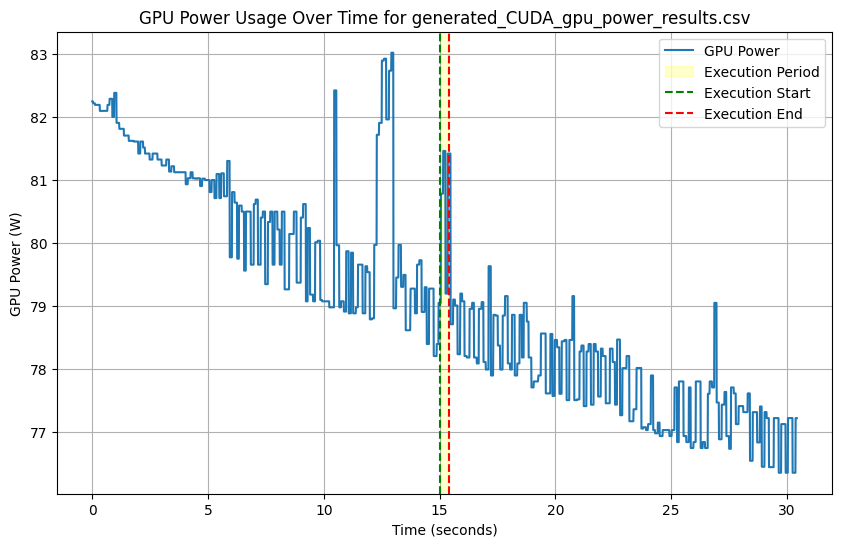

Start time: 15.01 -- End time: 15.416

... Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 0.41 seconds
Total GPU energy consumption for generated_CUDA_gpu_power_results.csv:
  0.000009 kWh
  0.0089 Wh
  32.20 J
Average GPU power: 80.46 W
Total Energy During Exe Runtime:   32.20 J
----------------------------------------------------------------------------------------------------------------------------------------

***** Execution failed.
Error message: 
Program exited with return code: -11 Segmentation fault detected.


----- SELF-CORRECTION: 1 -----


----- ERROR SELF-CORRECTION -----

PROMPT (error correction, token count: 10487): [BEGIN CONTEXT KNOWLEDGE] [BEGIN GENERAL CUDA PROGRAMMING CONTEXT] Chapter 5. Programming Model This chapter introduces the main concepts behind the CUDA programming model by outlining how they are exposed in C++. An extensive description of CUDA C++ is given in Programming Interface. Full code for the vector add

KeyboardInterrupt: 

In [6]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, source_lang, target_lang, model, num_ctx,
    llm_source, use_context, context_knowledge_selection, code_compiler,
    code_compiler_kwds, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback
) = experimental_setup()


# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BEGIN GENERAL CUDA PROGRAMMING CONTEXT] " + prompts.get_codeknowledge("cuda") + " [/END GENERAL CUDA PROGRAMMING CONTEXT]\n\n "
input_context = input_context + " [BEGIN CUDA OPTIMIZATION CONTEXT] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + " [/END CUDA OPTIMIZATION CONTEXT]\n\n "


# DEFINE PROMPT TEMPLATES
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))


# LOAD INPUT CODE TO TRANSLATE
input_code_folder = "HeCBench/" + app_folder_name + "/"
input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()

# SPECIFY OUTPUT CODE SAVE
directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + directory + "/" + file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
meta_data_file += "\n\nLLM Prompt: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

print("\n" + meta_data_file + "\n")

print("\n\n" + color.BOLD + "***** BEGIN THE LASSI PIPELINE*****" + color.END + "\n\n")

# RUN PIPELINE
complete = lassi.pipeline.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    num_ctx,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    directory,
    file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure, 
    test_code_first,
    yes_power_feedback
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

### TESTING ONLY

In [14]:
# energy = lassi.getpower.GetGPUpower.idlepower(10)
# print(energy)

# TESTING ONLY
# Names of the CSV files
'''
files = ['translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/generated_OMP_gpu_power_results.csv',
             #'./gpu_power_results_mtdv4.csv',
            ]
# Plot power usage and calculate energy
for file_name in files:
    inference_duration = lassi.getpower.plot_gpu_power(file_name)
    total_energy_joules, ave_power = lassi.getpower.calculate_total_energy(file_name)
    
    # Convert energy units
    total_energy_wh = total_energy_joules / 3600  # Convert from Joules to Watt-hours
    total_energy_kwh = total_energy_wh / 1000  # Convert from Watt-hours to Kilowatt-hours
    
    print(f"Inference duration: {inference_duration:.2f} seconds")
    print(f"Total GPU energy consumption for {file_name}:")
    print(f"  {total_energy_kwh:.6f} kWh")
    print(f"  {total_energy_wh:.4f} Wh")
    print(f"  {total_energy_joules:.2f} J")
    print(f"Average GPU power: {ave_power:.2f} W")
    print("----------------------------------------------------------------------------------------------------------------------------------------")
'''

# TESTING: code execution with power
'''
# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"
exe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"
# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext
input_parameters = [""]
power_measure = True
code_source = "target"
target_lang = "CUDA"

lassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)
'''

'\n# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"\nexe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"\n# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext\ninput_parameters = [""]\npower_measure = True\ncode_source = "target"\ntarget_lang = "CUDA"\n\nlassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)\n'